<a href="https://colab.research.google.com/github/Razae786/NLP-Lab-FA23-BAI-064/blob/main/NLP_Lab07_Tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FA23-bai-064**

# NLP Lab 07 — POS Tagging & Named Entity Recognition
Run all cells top to bottom (Runtime → Run all). Cell 1 installs spaCy + `en_core_web_sm`.
HTML outputs are saved next to the notebook: `entities.html`, `entities_filtered.html`, `entities_custom.html`, `dependency.html`, `entities_final.html`, plus `output.json`.

## Setup

In [1]:
!pip install -q spacy matplotlib
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import json
import pathlib
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import spacy
from spacy import displacy
from IPython.display import HTML, display

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:                      # model not installed yet
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

print("spaCy", spacy.__version__, "| pipeline:", nlp.pipe_names)

spaCy 3.8.18 | pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


# Task 1: Coarse vs Fine-Grained POS Tags

In [3]:
# (a) tokens with coarse .pos_
sentence = "The quick brown fox jumped over the lazy dogs near the river."
doc = nlp(sentence)

print(f"{'TOKEN':<10}{'POS (coarse)'}")
print("-" * 25)
for tok in doc:
    print(f"{tok.text:<10}{tok.pos_}")

TOKEN     POS (coarse)
-------------------------
The       DET
quick     ADJ
brown     ADJ
fox       NOUN
jumped    VERB
over      ADP
the       DET
lazy      ADJ
dogs      NOUN
near      ADP
the       DET
river     NOUN
.         PUNCT


In [4]:
# (b) same tokens, .pos_ and .tag_ in two columns
print(f"{'TOKEN':<10}{'POS (coarse)':<15}{'TAG (fine)'}")
print("-" * 35)
for tok in doc:
    print(f"{tok.text:<10}{tok.pos_:<15}{tok.tag_}")

TOKEN     POS (coarse)   TAG (fine)
-----------------------------------
The       DET            DT
quick     ADJ            JJ
brown     ADJ            JJ
fox       NOUN           NN
jumped    VERB           VBD
over      ADP            IN
the       DET            DT
lazy      ADJ            JJ
dogs      NOUN           NNS
near      ADP            IN
the       DET            DT
river     NOUN           NN
.         PUNCT          .


In [5]:
# (c) spacy.explain() for every unique .pos_ and .tag_
pos_values = sorted({tok.pos_ for tok in doc})
tag_values = sorted({tok.tag_ for tok in doc})

print("UNIQUE COARSE POS TAGS")
for p in pos_values:
    print(f"  {p:<6} -> {spacy.explain(p)}")

print("\nUNIQUE FINE-GRAINED TAGS")
for t in tag_values:
    print(f"  {t:<6} -> {spacy.explain(t)}")

UNIQUE COARSE POS TAGS
  ADJ    -> adjective
  ADP    -> adposition
  DET    -> determiner
  NOUN   -> noun
  PUNCT  -> punctuation
  VERB   -> verb

UNIQUE FINE-GRAINED TAGS
  .      -> punctuation mark, sentence closer
  DT     -> determiner
  IN     -> conjunction, subordinating or preposition
  JJ     -> adjective (English), other noun-modifier (Chinese)
  NN     -> noun, singular or mass
  NNS    -> noun, plural
  VBD    -> verb, past tense


In [6]:
# (d) distinct .tag_ values per .pos_, and tokens whose coarse POS maps to >1 fine tag
tags_by_pos = defaultdict(set)
for tok in doc:
    tags_by_pos[tok.pos_].add(tok.tag_)

print("DISTINCT FINE TAGS PER COARSE POS")
print(f"{'POS':<8}{'COUNT':<8}TAGS")
for pos in sorted(tags_by_pos):
    tags = sorted(tags_by_pos[pos])
    print(f"{pos:<8}{len(tags):<8}{', '.join(tags)}")

notable = [tok for tok in doc if len(tags_by_pos[tok.pos_]) > 1]

print("\nTOKENS WHOSE COARSE POS HAS MORE THAN ONE FINE TAG")
if notable:
    for tok in notable:
        print(f"  {tok.text:<8} pos={tok.pos_:<6} tag={tok.tag_:<6} -> {spacy.explain(tok.tag_)}")
else:
    print("  (none for this sentence/model version)")
print(f"\nCount of such tokens: {len(notable)}")

DISTINCT FINE TAGS PER COARSE POS
POS     COUNT   TAGS
ADJ     1       JJ
ADP     1       IN
DET     1       DT
NOUN    2       NN, NNS
PUNCT   1       .
VERB    1       VBD

TOKENS WHOSE COARSE POS HAS MORE THAN ONE FINE TAG
  fox      pos=NOUN   tag=NN     -> noun, singular or mass
  dogs     pos=NOUN   tag=NNS    -> noun, plural
  river    pos=NOUN   tag=NN     -> noun, singular or mass

Count of such tokens: 3


# Task 2: Tag Frequency Analysis

In [7]:
paragraph = ("Ali bought three fresh apples. He carefully washed them and quickly "
             "shared them with his friends. Everyone happily enjoyed the sweet fruit.")
doc2 = nlp(paragraph)

# (a) .pos_ counts -> dictionary
pos_counts = {}
for tok in doc2:
    pos_counts[tok.pos_] = pos_counts.get(tok.pos_, 0) + 1

# (b) .tag_ counts -> separate dictionary
tag_counts = {}
for tok in doc2:
    tag_counts[tok.tag_] = tag_counts.get(tok.tag_, 0) + 1

print("pos_counts:", pos_counts)
print("tag_counts:", tag_counts)

pos_counts: {'PROPN': 1, 'VERB': 4, 'NUM': 1, 'ADJ': 2, 'NOUN': 3, 'PUNCT': 3, 'PRON': 5, 'ADV': 3, 'CCONJ': 1, 'ADP': 1, 'DET': 1}
tag_counts: {'NNP': 1, 'VBD': 4, 'CD': 1, 'JJ': 2, 'NNS': 2, '.': 3, 'PRP': 3, 'RB': 3, 'CC': 1, 'IN': 1, 'PRP$': 1, 'NN': 2, 'DT': 1}


In [8]:
# (c) both dictionaries sorted most frequent -> least frequent
pos_sorted = dict(sorted(pos_counts.items(), key=lambda kv: kv[1], reverse=True))
tag_sorted = dict(sorted(tag_counts.items(), key=lambda kv: kv[1], reverse=True))

print("COARSE POS (most -> least frequent)")
for k, v in pos_sorted.items():
    print(f"  {k:<8}{v}")

print("\nFINE TAG (most -> least frequent)")
for k, v in tag_sorted.items():
    print(f"  {k:<8}{v}")

COARSE POS (most -> least frequent)
  PRON    5
  VERB    4
  NOUN    3
  PUNCT   3
  ADV     3
  ADJ     2
  PROPN   1
  NUM     1
  CCONJ   1
  ADP     1
  DET     1

FINE TAG (most -> least frequent)
  VBD     4
  .       3
  PRP     3
  RB      3
  JJ      2
  NNS     2
  NN      2
  NNP     1
  CD      1
  CC      1
  IN      1
  PRP$    1
  DT      1


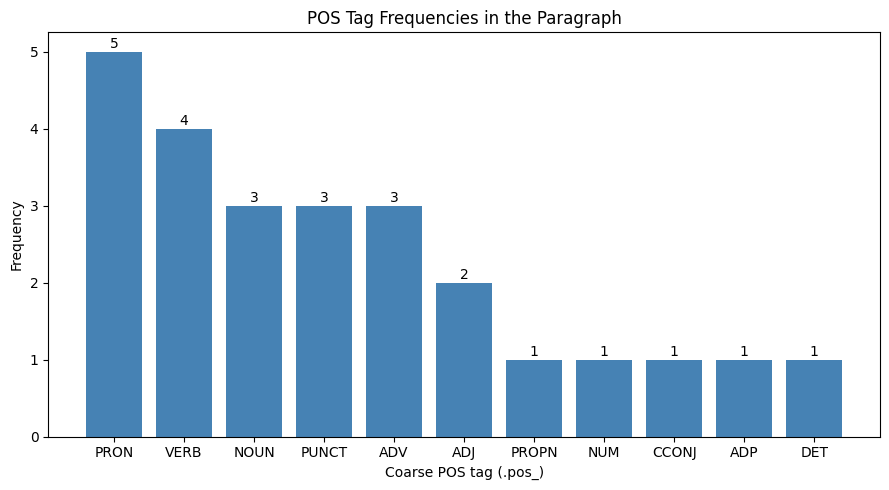

In [9]:
# (d) bar chart of .pos_ frequencies
labels = list(pos_sorted.keys())
values = list(pos_sorted.values())

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, values, color="steelblue")
for b, v in zip(bars, values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.05, str(v), ha="center")
plt.xlabel("Coarse POS tag (.pos_)")
plt.ylabel("Frequency")
plt.title("POS Tag Frequencies in the Paragraph")
plt.tight_layout()
plt.show()

# Task 3: Context-Dependent Tagging

In [10]:
sentences = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play.",
]
docs3 = [nlp(s) for s in sentences]

# (a) "book"
print("BOOK occurrences:")
for i, d in enumerate(docs3):
    for t in d:
        if t.text.lower() == "book":
            print(f"  sentence {i + 1}: pos_={t.pos_:<6} tag_={t.tag_:<5} -> {spacy.explain(t.tag_)}")

# (b) "run"
print("\nRUN occurrences:")
for i, d in enumerate(docs3):
    for t in d:
        if t.text.lower() == "run":
            print(f"  sentence {i + 1}: pos_={t.pos_:<6} tag_={t.tag_:<5} -> {spacy.explain(t.tag_)}")

BOOK occurrences:
  sentence 1: pos_=VERB   tag_=VB    -> verb, base form
  sentence 2: pos_=NOUN   tag_=NN    -> noun, singular or mass

RUN occurrences:
  sentence 3: pos_=VERB   tag_=VBP   -> verb, non-3rd person singular present
  sentence 4: pos_=NOUN   tag_=NN    -> noun, singular or mass


In [11]:
# (c) reusable function -> list of (sentence_index, pos_, tag_)
def compare_word(word, sentences):
    results = []
    for i, s in enumerate(sentences):
        for t in nlp(s):
            if t.text.lower() == word.lower():
                results.append((i, t.pos_, t.tag_))
    return results

print("book:", compare_word("book", sentences))
print("run :", compare_word("run", sentences))

book: [(0, 'VERB', 'VB'), (1, 'NOUN', 'NN')]
run : [(2, 'VERB', 'VBP'), (3, 'NOUN', 'NN')]


In [12]:
# (d) two extra ambiguous words, two sentences each
extra = {
    "light": ["Turn on the light.", "The bag is light."],
    "play":  ["They play football.", "We watched a play."],
}
for w, ss in extra.items():
    print(f"\n--- {w} ---")
    for idx, pos, tag in compare_word(w, ss):
        print(f"  sentence index {idx}: {ss[idx]!r} -> POS={pos}, TAG={tag} ({spacy.explain(tag)})")


--- light ---
  sentence index 0: 'Turn on the light.' -> POS=NOUN, TAG=NN (noun, singular or mass)
  sentence index 1: 'The bag is light.' -> POS=ADJ, TAG=JJ (adjective (English), other noun-modifier (Chinese))

--- play ---
  sentence index 0: 'They play football.' -> POS=VERB, TAG=VBP (verb, non-3rd person singular present)
  sentence index 1: 'We watched a play.' -> POS=NOUN, TAG=NN (noun, singular or mass)


# Task 4: Filtering Noise Tokens

In [13]:
# (a) raw output, noise included
messy = " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "
doc4 = nlp(messy)

print(f"{'TOKEN':<16}{'POS'}")
print("-" * 26)
for t in doc4:
    print(f"{t.text!r:<16}{t.pos_}")
print("\nTotal tokens:", len(doc4))

TOKEN           POS
--------------------------
' '             SPACE
'Hello'         INTJ
'!'             PUNCT
'!'             PUNCT
'!'             PUNCT
'The'           DET
'price'         NOUN
'is'            AUX
'$'             SYM
'45.50'         NUM
'...'           PUNCT
'('             PUNCT
'really'        ADV
'?'             PUNCT
')'             PUNCT
'\n\n '         SPACE
'Is'            AUX
'it'            PRON
'worth'         ADJ
'it'            PRON
'?'             PUNCT
'xyz123'        PROPN
'@@'            PROPN

Total tokens: 23


In [14]:
# (b) remove SPACE, PUNCT, X
noise = {"SPACE", "PUNCT", "X"}
cleaned = [t.text for t in doc4 if t.pos_ not in noise]
print("Cleaned tokens:", cleaned)

# (c) how many removed / percentage
removed = len(doc4) - len(cleaned)
pct = 100 * removed / len(doc4)
print(f"Removed {removed} of {len(doc4)} tokens ({pct:.1f}%)")

Cleaned tokens: ['Hello', 'The', 'price', 'is', '$', '45.50', 'really', 'Is', 'it', 'worth', 'it', 'xyz123', '@@']
Removed 10 of 23 tokens (43.5%)


In [15]:
# (d) reusable function + test on a second noisy text
def clean_pos(text, remove=("SPACE", "PUNCT", "X")):
    return [(t.text, t.pos_) for t in nlp(text) if t.pos_ not in remove]

test2 = "  Wow!!!   Did you see   that ???  ## @@@ qwzx99 ... $$$  "
raw2 = nlp(test2)
kept2 = clean_pos(test2)

print("Raw tokens    :", [(t.text, t.pos_) for t in raw2])
print("Cleaned tokens:", kept2)
print(f"Noise tokens removed: {len(raw2) - len(kept2)} (task requires at least 5)")

Raw tokens    : [('  ', 'SPACE'), ('Wow', 'INTJ'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('!', 'PUNCT'), ('  ', 'SPACE'), ('Did', 'AUX'), ('you', 'PRON'), ('see', 'VERB'), ('  ', 'SPACE'), ('that', 'PRON'), ('?', 'PUNCT'), ('?', 'PUNCT'), ('?', 'PUNCT'), (' ', 'SPACE'), ('#', 'SYM'), ('#', 'NOUN'), ('@@@', 'PROPN'), ('qwzx99', 'NOUN'), ('...', 'PUNCT'), ('$', 'SYM'), ('$', 'SYM'), ('$', 'SYM'), (' ', 'SPACE')]
Cleaned tokens: [('Wow', 'INTJ'), ('Did', 'AUX'), ('you', 'PRON'), ('see', 'VERB'), ('that', 'PRON'), ('#', 'SYM'), ('#', 'NOUN'), ('@@@', 'PROPN'), ('qwzx99', 'NOUN'), ('$', 'SYM'), ('$', 'SYM'), ('$', 'SYM')]
Noise tokens removed: 12 (task requires at least 5)


# Task 5: Extracting Specific Parts of Speech

In [16]:
text5 = ("Fatima quickly opened the old wooden door and slowly walked into the dark room. "
         "She carefully placed a small lamp on the heavy table.")
doc5 = nlp(text5)

# (a) nouns (NOUN + PROPN)
print("NOUNS / PROPER NOUNS:")
for t in doc5:
    if t.pos_ in ("NOUN", "PROPN"):
        print(f"  {t.text:<10}{t.pos_}")

# (b) verbs with lemmas
print("\nVERBS (token -> lemma):")
for t in doc5:
    if t.pos_ == "VERB":
        print(f"  {t.text:<10}-> {t.lemma_}")

NOUNS / PROPER NOUNS:
  Fatima    PROPN
  door      NOUN
  room      NOUN
  lamp      NOUN
  table     NOUN

VERBS (token -> lemma):
  opened    -> open
  walked    -> walk
  placed    -> place


In [17]:
# (c) adjective directly followed by a noun (checked with token indices)
pairs = []
for t in doc5:
    if t.pos_ == "ADJ" and t.i + 1 < len(doc5):
        nxt = doc5[t.i + 1]
        if nxt.pos_ in ("NOUN", "PROPN"):
            pairs.append(f"{t.text} {nxt.text}")
print("Adjective-noun pairs:", pairs)

# bonus: full adjective chain before each noun (e.g. 'old wooden door')
chains = []
for t in doc5:
    if t.pos_ in ("NOUN", "PROPN"):
        j = t.i - 1
        adjs = []
        while j >= 0 and doc5[j].pos_ == "ADJ":
            adjs.insert(0, doc5[j].text)
            j -= 1
        if adjs:
            chains.append(" ".join(adjs + [t.text]))
print("Full chains          :", chains)

Adjective-noun pairs: ['wooden door', 'dark room', 'small lamp', 'heavy table']
Full chains          : ['old wooden door', 'dark room', 'small lamp', 'heavy table']


In [18]:
# (d) summary table
c = Counter(t.pos_ for t in doc5)
print(f"{'CATEGORY':<12}{'COUNT':>6}")
print("-" * 18)
print(f"{'Nouns':<12}{c['NOUN'] + c['PROPN']:>6}   (NOUN + PROPN)")
print(f"{'Verbs':<12}{c['VERB']:>6}")
print(f"{'Adjectives':<12}{c['ADJ']:>6}")
print(f"{'Adverbs':<12}{c['ADV']:>6}")

CATEGORY     COUNT
------------------
Nouns            5   (NOUN + PROPN)
Verbs            3
Adjectives       5
Adverbs          3


# Task 6: Basic Named Entity Recognition

In [19]:
text6 = ("Imran Khan visited Google headquarters in California on March 3, 2019, and discussed "
         "a $2 million investment for Pakistan. Later, Microsoft and Amazon announced new offices in Lahore.")
doc6 = nlp(text6)

# (a) every entity with label and character offsets
print(f"{'TEXT':<22}{'LABEL':<10}{'START':<7}{'END'}")
print("-" * 45)
for e in doc6.ents:
    print(f"{e.text:<22}{e.label_:<10}{e.start_char:<7}{e.end_char}")

TEXT                  LABEL     START  END
---------------------------------------------
Khan                  PERSON    6      10
Google                ORG       19     25
California            GPE       42     52
March 3, 2019         DATE      56     69
$2 million            MONEY     87     97
Pakistan              GPE       113    121
Microsoft             ORG       130    139
Amazon                ORG       144    150
Lahore                GPE       176    182


In [20]:
# (b) meaning of every unique label
for lab in sorted({e.label_ for e in doc6.ents}):
    print(f"  {lab:<10}-> {spacy.explain(lab)}")

  DATE      -> Absolute or relative dates or periods
  GPE       -> Countries, cities, states
  MONEY     -> Monetary values, including unit
  ORG       -> Companies, agencies, institutions, etc.
  PERSON    -> People, including fictional


In [21]:
# (c) group entities by label
by_label = defaultdict(list)
for e in doc6.ents:
    by_label[e.label_].append(e.text)
print(dict(by_label))

# (d) counts + label with highest count (ties reported)
counts = Counter(e.label_ for e in doc6.ents)
print("\nCounts:", dict(counts))
top_n = max(counts.values())
top_labels = [l for l, n in counts.items() if n == top_n]
print(f"Highest count: {top_n} -> {top_labels}")

{'PERSON': ['Khan'], 'ORG': ['Google', 'Microsoft', 'Amazon'], 'GPE': ['California', 'Pakistan', 'Lahore'], 'DATE': ['March 3, 2019'], 'MONEY': ['$2 million']}

Counts: {'PERSON': 1, 'ORG': 3, 'GPE': 3, 'DATE': 1, 'MONEY': 1}
Highest count: 3 -> ['ORG', 'GPE']


# Task 7: Visualizing Entities with displaCy

In [22]:
text7 = ("Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans "
         "to invest 500 million dollars across Asia by 2025.")
doc7 = nlp(text7)

def save_html(doc_or_span, filename, **kwargs):
    # page=True -> complete standalone HTML page that opens in any browser
    html_page = displacy.render(doc_or_span, jupyter=False, page=True, **kwargs)
    pathlib.Path(filename).write_text(html_page, encoding="utf-8")
    # inline preview in the notebook
    display(HTML(displacy.render(doc_or_span, jupyter=False, page=False, **kwargs)))
    print(f"saved -> {filename}")

# (a) all entities
save_html(doc7, "entities.html", style="ent")

saved -> entities.html


In [23]:
# (b) only ORG and GPE highlighted
save_html(doc7, "entities_filtered.html", style="ent",
          options={"ents": ["ORG", "GPE"]})

saved -> entities_filtered.html


In [24]:
# (c) ORG = orange, GPE = light green
save_html(doc7, "entities_custom.html", style="ent",
          options={"ents": ["ORG", "GPE"],
                   "colors": {"ORG": "orange", "GPE": "lightgreen"}})

saved -> entities_custom.html


In [25]:
# (d) dependency tree of the FIRST sentence only
first_sent = list(doc7.sents)[0]
print("Sentence:", first_sent.text)
save_html(first_sent, "dependency.html", style="dep")

Sentence: Apple opened a new store in Karachi in June 2023.


saved -> dependency.html


# Task 8: Extending the Model with EntityRuler

In [26]:
text8 = ("Dr. Zainab works at LabTech Solutions and uses the Python library NumPy and the framework "
         "TensorFlow. Her colleague Abbas prefers PyTorch and Pandas.")
tech_terms = ["NumPy", "TensorFlow", "PyTorch", "Pandas"]

def tech_report(doc):
    for term in tech_terms:
        for t in doc:
            if t.text == term:
                if t.ent_type_ == "":
                    status = "MISSED (no entity)"
                elif t.ent_type_ == "TECH":
                    status = "OK -> TECH"
                else:
                    status = f"MISLABELLED as {t.ent_type_}"
                print(f"  {term:<12}{status}")

# (a) plain pretrained model
plain_doc = nlp(text8)
print("Entities from the plain model:")
for e in plain_doc.ents:
    print(f"  {e.text:<25}{e.label_}")
print("\nTech-term status:")
tech_report(plain_doc)

Entities from the plain model:
  Zainab                   PERSON
  LabTech Solutions        ORG
  Abbas                    PERSON
  PyTorch                  PERSON
  Pandas                   PERSON

Tech-term status:
  NumPy       MISSED (no entity)
  TensorFlow  MISSED (no entity)
  PyTorch     MISLABELLED as PERSON
  Pandas      MISLABELLED as PERSON


In [27]:
# (b) EntityRuler with label TECH (string patterns, one per term)
patterns = [{"label": "TECH", "pattern": t} for t in tech_terms]

nlp_ruler = spacy.load("en_core_web_sm")
ruler = nlp_ruler.add_pipe("entity_ruler", before="ner")
ruler.add_patterns(patterns)
print("Pipeline:", nlp_ruler.pipe_names)

# (c) reprocess and confirm
ruler_doc = nlp_ruler(text8)
print("\nEntities with EntityRuler:")
for e in ruler_doc.ents:
    print(f"  {e.text:<25}{e.label_}")
print("\nTech-term status:")
tech_report(ruler_doc)

Pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'entity_ruler', 'ner']

Entities with EntityRuler:
  Zainab                   PERSON
  LabTech Solutions        ORG
  NumPy                    TECH
  TensorFlow               TECH
  Abbas                    PERSON
  PyTorch                  TECH
  Pandas                   TECH

Tech-term status:
  NumPy       OK -> TECH
  TensorFlow  OK -> TECH
  PyTorch     OK -> TECH
  Pandas      OK -> TECH


In [28]:
# (d) overwrite_ents and ruler position.
# NOTE: spaCy's EntityRuler default is overwrite_ents=False.
# overwrite_ents only matters when entities ALREADY exist when the ruler runs, i.e. after="ner".
# To make that visible, one demo-only pattern is added that conflicts with an NER entity.
demo_patterns = patterns + [{"label": "TECH", "pattern": "LabTech Solutions"}]

def build(position, overwrite):
    n = spacy.load("en_core_web_sm")
    r = n.add_pipe("entity_ruler", config={"overwrite_ents": overwrite}, **{position: "ner"})
    r.add_patterns(demo_patterns)
    return n

configs = [
    ("before ner, overwrite_ents=False", "before", False),
    ("before ner, overwrite_ents=True",  "before", True),
    ("after  ner, overwrite_ents=False", "after",  False),
    ("after  ner, overwrite_ents=True",  "after",  True),
]
for label, position, ow in configs:
    d = build(position, ow)(text8)
    print(f"\n--- {label} ---")
    for e in d.ents:
        print(f"  {e.text:<25}{e.label_}")


--- before ner, overwrite_ents=False ---
  Zainab                   PERSON
  LabTech Solutions        TECH
  NumPy                    TECH
  TensorFlow               TECH
  Abbas                    PERSON
  PyTorch                  TECH
  Pandas                   TECH

--- before ner, overwrite_ents=True ---
  Zainab                   PERSON
  LabTech Solutions        TECH
  NumPy                    TECH
  TensorFlow               TECH
  Abbas                    PERSON
  PyTorch                  TECH
  Pandas                   TECH

--- after  ner, overwrite_ents=False ---
  Zainab                   PERSON
  LabTech Solutions        ORG
  NumPy                    TECH
  TensorFlow               TECH
  Abbas                    PERSON
  PyTorch                  PERSON
  Pandas                   PERSON

--- after  ner, overwrite_ents=True ---
  Zainab                   PERSON
  LabTech Solutions        TECH
  NumPy                    TECH
  TensorFlow               TECH
  Abbas          

# Task 9: Complete Pipeline — Raw Text to Structured Information

In [29]:
text9 = ("Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket "
         "from Texas next month. Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%.")

# (a) cleaned tokens with .pos_ and .tag_
def clean_tokens(text, remove=("SPACE", "PUNCT", "X")):
    return [{"text": t.text, "pos": t.pos_, "tag": t.tag_}
            for t in nlp(text) if t.pos_ not in remove]

tokens9 = clean_tokens(text9)
for tok in tokens9:
    print(f"{tok['text']:<12}{tok['pos']:<7}{tok['tag']}")

Elon        PROPN  NNP
Musk        PROPN  NNP
the         DET    DT
CEO         NOUN   NN
of          ADP    IN
Tesla       PROPN  NNP
announced   VERB   VBN
on          ADP    IN
Tuesday     PROPN  NNP
that        SCONJ  IN
SpaceX      PROPN  NNP
will        AUX    MD
launch      VERB   VB
a           DET    DT
Falcon      PROPN  NNP
rocket      NOUN   NN
from        ADP    IN
Texas       PROPN  NNP
next        ADJ    JJ
month       NOUN   NN
Investors   NOUN   NNS
in          ADP    IN
London      PROPN  NNP
and         CCONJ  CC
Tokyo       PROPN  NNP
reacted     VERB   VBD
quickly     ADV    RB
and         CCONJ  CC
Tesla       PROPN  NNP
shares      NOUN   NNS
rose        VERB   VBD
by          ADP    IN
4           NUM    CD
%           NOUN   NN


In [30]:
# (b) EntityRuler with PRODUCT patterns; ruler + model results combined
nlp9 = spacy.load("en_core_web_sm")
ruler9 = nlp9.add_pipe("entity_ruler", before="ner", config={"overwrite_ents": True})
ruler9.add_patterns([
    {"label": "PRODUCT", "pattern": "Falcon"},
    {"label": "PRODUCT", "pattern": [{"LOWER": "tesla"}, {"LOWER": "shares"}]},
])

doc9 = nlp9(text9)
print("Final entities (model + ruler):")
for e in doc9.ents:
    print(f"  {e.text:<18}{e.label_}")

Final entities (model + ruler):
  Elon Musk         PERSON
  Tesla             ORG
  Tuesday           DATE
  SpaceX            PERSON
  Falcon            PRODUCT
  Texas             GPE
  next month        DATE
  London            GPE
  Tokyo             GPE
  Tesla shares      PRODUCT
  4%                PERCENT


In [31]:
# (c) structured output -> output.json
entities9 = [{"text": e.text, "label": e.label_, "start": e.start_char, "end": e.end_char}
             for e in doc9.ents]
pos_counts9 = dict(Counter(t["pos"] for t in tokens9))      # counted on the CLEANED tokens

output = {"tokens": tokens9, "entities": entities9, "pos_counts": pos_counts9}
pathlib.Path("output.json").write_text(json.dumps(output, indent=2), encoding="utf-8")
print("saved -> output.json")
print(json.dumps(pos_counts9, indent=2))

saved -> output.json
{
  "PROPN": 10,
  "DET": 2,
  "NOUN": 6,
  "ADP": 5,
  "VERB": 4,
  "SCONJ": 1,
  "AUX": 1,
  "ADJ": 1,
  "CCONJ": 2,
  "ADV": 1,
  "NUM": 1
}


In [32]:
# (d) displaCy with custom colours + entity -> sentence loop
colors9 = {"PERSON": "#ffb3ba", "ORG": "#bae1ff", "GPE": "#baffc9", "PRODUCT": "#ffdfba"}
save_html(doc9, "entities_final.html", style="ent",
          options={"ents": list(colors9), "colors": colors9})

print("\nEntity -> sentence it came from:")
for e in doc9.ents:
    print(f"  {e.text:<14}({e.label_:<8}) in: {e.sent.text.strip()}")

saved -> entities_final.html

Entity -> sentence it came from:
  Elon Musk     (PERSON  ) in: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
  Tesla         (ORG     ) in: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
  Tuesday       (DATE    ) in: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
  SpaceX        (PERSON  ) in: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
  Falcon        (PRODUCT ) in: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
  Texas         (GPE     ) in: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
  next month    (DATE    ) in: Elon Musk, the CEO of Tesla, announced on 